In [8]:
import numpy as np
import emcee

# z_d
z = np.array([
    0.230,  # WGD2038
    0.295,  # RXJ1131
    0.311,  # PG1115
    0.407,  # J1433
    0.454,  # HE0435
    0.590,  # J1537
    0.597,  # DES0408
    0.630,  # B1608
    0.657,  # WFI2033
    0.729,  # HE1104
    0.745   # J1206
])

# H0 values
H0 = np.array([
    65.0,
    78.2,
    81.1,
    73.2,
    71.7,
    75.5,
    74.2,
    71.0,
    71.6,
    64.2,
    68.9
])

# symmetrised 1-sigma uncertainties
sigma = np.array([
    18.5,
    3.4,
    7.55,
    4.75,
    4.65,
    7.55,
    2.85,
    3.10,
    4.35,
    5.40,
    5.25
])

def log_prior(theta):
    a, b = theta

    if 40.0 < a < 120.0 and -100.0 < b < 100.0:
        return 0.0

    return -np.inf


def log_likelihood(theta, z, H0, sigma):
    a, b = theta

    model = a + b * z

    var = sigma**2

    return -0.5 * np.sum(
        (H0 - model)**2 / var
        + np.log(2.0 * np.pi * var)
    )


def log_probability(theta, z, H0, sigma):
    lp = log_prior(theta)

    if not np.isfinite(lp):
        return -np.inf

    return lp + log_likelihood(theta, z, H0, sigma)


# ---------- initialise walkers ----------

nwalkers = 32
ndim = 2

# weighted least-squares starting point
w = 1.0 / sigma**2

X = np.vstack([np.ones_like(z), z]).T

C = np.linalg.inv(X.T @ (w[:, None] * X))

beta = C @ (X.T @ (w * H0))

a0, b0 = beta

p0 = np.column_stack([
    a0 + 1e-3 * np.random.randn(nwalkers),
    b0 + 1e-3 * np.random.randn(nwalkers)
])

# ---------- run emcee ----------

sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_probability,
    args=(z, H0, sigma)
)

sampler.run_mcmc(p0, 20000, progress=True)

# ---------- analyse ----------

flat = sampler.get_chain(discard=5000,
                         thin=20,
                         flat=True)

a_chain = flat[:, 0]
b_chain = flat[:, 1]

for name, chain in [
    ("a", a_chain),
    ("b", b_chain),
]:
    q16, q50, q84 = np.percentile(chain, [16, 50, 84])
    print(
        f"{name}: {q50:.3f} "
        f"+{q84-q50:.3f} "
        f"-{q50-q16:.3f}"
    )

print("P(b < 0) =", np.mean(b_chain < 0))

100%|██████████| 20000/20000 [00:32<00:00, 606.93it/s]

a: 83.389 +5.094 -5.033
b: -19.277 +8.967 -8.924
P(b < 0) = 0.9836666666666667


In [3]:
import numpy as np
import emcee

# ============================================================
# Data
# ============================================================

z = np.array([
    0.230,  # WGD2038-4008
    0.295,  # RXJ1131-1231
    0.311,  # PG1115+080
    0.407,  # SDSS J1433+6007
    0.454,  # HE0435-1223
    0.590,  # J1537-3010
    0.597,  # DES J0408-5354
    0.630,  # B1608+656
    0.657,  # WFI2033-4723
    0.729,  # HE1104-1805
    0.745   # SDSS J1206+4332
])

H0 = np.array([
    65.0,
    78.2,
    81.1,
    73.2,
    71.7,
    75.5,
    74.2,
    71.0,
    71.6,
    64.2,
    68.9
])

# lower errors
sigma_minus = np.array([
    14.0,
    3.4,
    7.1,
    4.7,
    4.5,
    5.8,
    3.0,
    3.3,
    4.9,
    5.0,
    5.1
])

# upper errors
sigma_plus = np.array([
    23.0,
    3.4,
    8.0,
    4.8,
    4.8,
    9.3,
    2.7,
    2.9,
    3.8,
    5.8,
    5.4
])

# ============================================================
# Model
# ============================================================

def model(theta, z):
    a, b, lnsig_int = theta
    return a + b * z


# ============================================================
# Prior
# ============================================================

def log_prior(theta):

    a, b, lnsig_int = theta

    if not (40.0 < a < 120.0):
        return -np.inf

    if not (-100.0 < b < 100.0):
        return -np.inf

    if not (-20.0 < lnsig_int < 5.0):
        return -np.inf

    return 0.0


# ============================================================
# Asymmetric likelihood
#
# If model < datum:
#     use lower error bar
#
# If model > datum:
#     use upper error bar
#
# This is equivalent to a split-normal likelihood.
# ============================================================

def log_likelihood(theta,
                   z,
                   H0,
                   sigma_minus,
                   sigma_plus):

    a, b, lnsig_int = theta

    pred = model(theta, z)

    resid = H0 - pred

    sigma_obs = np.where(
        resid >= 0.0,
        sigma_minus,
        sigma_plus
    )

    sigma_int = np.exp(lnsig_int)

    sigma_eff = np.sqrt(
        sigma_obs**2 +
        sigma_int**2
    )

    return np.sum(
        -0.5 * (resid / sigma_eff)**2
        - np.log(sigma_eff)
    )


# ============================================================
# Posterior
# ============================================================

def log_probability(theta,
                    z,
                    H0,
                    sigma_minus,
                    sigma_plus):

    lp = log_prior(theta)

    if not np.isfinite(lp):
        return -np.inf

    ll = log_likelihood(theta,
                        z,
                        H0,
                        sigma_minus,
                        sigma_plus)

    return lp + ll


# ============================================================
# Initial guess from symmetrised weighted fit
# ============================================================

sigma_sym = 0.5 * (sigma_minus + sigma_plus)

w = 1.0 / sigma_sym**2

X = np.column_stack([
    np.ones_like(z),
    z
])

cov = np.linalg.inv(
    X.T @ (w[:, None] * X)
)

beta = cov @ (X.T @ (w * H0))

a0, b0 = beta

print("Initial guess")
print("a =", a0)
print("b =", b0)

# ============================================================
# MCMC setup
# ============================================================

ndim = 3
nwalkers = 32
nsteps = 25000

p0 = np.column_stack([
    a0 + 1e-3*np.random.randn(nwalkers),
    b0 + 1e-3*np.random.randn(nwalkers),
    -3.0 + 1e-3*np.random.randn(nwalkers)
])

sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_probability,
    args=(
        z,
        H0,
        sigma_minus,
        sigma_plus
    )
)

# ============================================================
# Run
# ============================================================

sampler.run_mcmc(
    p0,
    nsteps,
    progress=True
)

# ============================================================
# Extract posterior
# ============================================================

flat = sampler.get_chain(
    discard=5000,
    thin=20,
    flat=True
)

a_chain = flat[:, 0]
b_chain = flat[:, 1]
sigma_int_chain = np.exp(flat[:, 2])

# ============================================================
# Summary statistics
# ============================================================

def summarize(name, chain):

    q16, q50, q84 = np.percentile(
        chain,
        [16, 50, 84]
    )

    print(
        f"{name}: "
        f"{q50:.3f} "
        f"+{q84-q50:.3f} "
        f"-{q50-q16:.3f}"
    )

summarize("a", a_chain)
summarize("b", b_chain)
summarize("sigma_int", sigma_int_chain)

print()
print("P(b < 0) =", np.mean(b_chain < 0))

# ============================================================
# Optional: save samples
# ============================================================

np.savez(
    "lens_fit_asymmetric.npz",
    a=a_chain,
    b=b_chain,
    sigma_int=sigma_int_chain
)

Initial guess
a = 83.37532960726708
b = -19.204989496631697


100%|██████████| 25000/25000 [00:49<00:00, 501.78it/s]

a: 83.378 +5.023 -5.061
b: -18.904 +9.149 -9.055
sigma_int: 0.000 +0.080 -0.000

P(b < 0) = 0.9799375


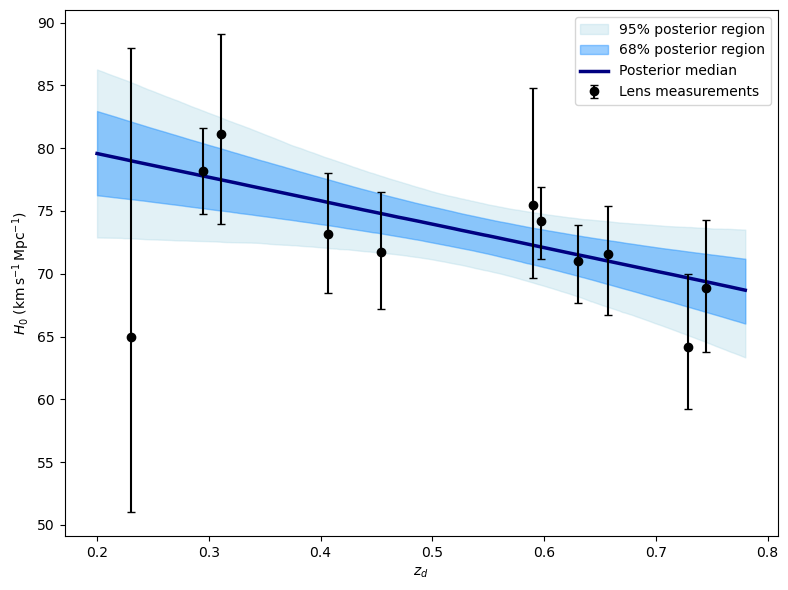

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Data
# --------------------------------------------------

z = np.array([
    0.230, 0.295, 0.311, 0.407, 0.454,
    0.590, 0.597, 0.630, 0.657, 0.729, 0.745
])

H0 = np.array([
    65.0, 78.2, 81.1, 73.2, 71.7,
    75.5, 74.2, 71.0, 71.6, 64.2, 68.9
])

sigma_minus = np.array([
    14.0, 3.4, 7.1, 4.7, 4.5,
    5.8, 3.0, 3.3, 4.9, 5.0, 5.1
])

sigma_plus = np.array([
    23.0, 3.4, 8.0, 4.8, 4.8,
    9.3, 2.7, 2.9, 3.8, 5.8, 5.4
])

# --------------------------------------------------
# Posterior predictive relation
# --------------------------------------------------

zgrid = np.linspace(0.20, 0.78, 500)

idx = np.random.choice(
    len(a_chain),
    size=min(10000, len(a_chain)),
    replace=False
)

pred = np.empty((len(idx), len(zgrid)))

for i, j in enumerate(idx):
    pred[i] = a_chain[j] + b_chain[j] * zgrid

median = np.percentile(pred, 50, axis=0)
low68  = np.percentile(pred, 16, axis=0)
high68 = np.percentile(pred, 84, axis=0)

low95  = np.percentile(pred, 2.5, axis=0)
high95 = np.percentile(pred, 97.5, axis=0)

# --------------------------------------------------
# Plot
# --------------------------------------------------

plt.figure(figsize=(8,6))

plt.fill_between(
    zgrid,
    low95,
    high95,
    color="lightblue",
    alpha=0.35,
    label="95% posterior region"
)

plt.fill_between(
    zgrid,
    low68,
    high68,
    color="dodgerblue",
    alpha=0.45,
    label="68% posterior region"
)

plt.plot(
    zgrid,
    median,
    color="navy",
    lw=2.5,
    label="Posterior median"
)

plt.errorbar(
    z,
    H0,
    yerr=[sigma_minus, sigma_plus],
    fmt="o",
    color="black",
    capsize=3,
    label="Lens measurements"
)

plt.xlabel(r"$z_d$")
plt.ylabel(r"$H_0\;(\mathrm{km\,s^{-1}\,Mpc^{-1}})$")

plt.legend()
plt.tight_layout()
plt.show()


In [5]:
import numpy as np
import emcee

# ============================================================
# DATA
# ============================================================

z = np.array([
    0.230,
    0.295,
    0.311,
    0.407,
    0.454,
    0.590,
    0.597,
    0.630,
    0.657,
    0.729,
    0.745
])

H0 = np.array([
    65.0,
    78.2,
    81.1,
    73.2,
    71.7,
    75.5,
    74.2,
    71.0,
    71.6,
    64.2,
    68.9
])

sigma_minus = np.array([
    14.0,
    3.4,
    7.1,
    4.7,
    4.5,
    5.8,
    3.0,
    3.3,
    4.9,
    5.0,
    5.1
])

sigma_plus = np.array([
    23.0,
    3.4,
    8.0,
    4.8,
    4.8,
    9.3,
    2.7,
    2.9,
    3.8,
    5.8,
    5.4
])

# ============================================================
# LINEAR MODEL
# ============================================================

def log_prior_line(theta):

    a, b, lnsig = theta

    if not (40 < a < 120):
        return -np.inf

    if not (-100 < b < 100):
        return -np.inf

    if not (-20 < lnsig < 5):
        return -np.inf

    return 0.0


def log_likelihood_line(theta):

    a, b, lnsig = theta

    model = a + b * z

    resid = H0 - model

    sigma_obs = np.where(
        resid >= 0,
        sigma_minus,
        sigma_plus
    )

    sigma_int = np.exp(lnsig)

    sigma_eff = np.sqrt(
        sigma_obs**2 +
        sigma_int**2
    )

    return np.sum(
        -0.5 * (resid / sigma_eff)**2
        - np.log(sigma_eff)
    )


def log_prob_line(theta):

    lp = log_prior_line(theta)

    if not np.isfinite(lp):
        return -np.inf

    return lp + log_likelihood_line(theta)

# ============================================================
# CONSTANT MODEL
# ============================================================

def log_prior_const(theta):

    c, lnsig = theta

    if not (40 < c < 120):
        return -np.inf

    if not (-20 < lnsig < 5):
        return -np.inf

    return 0.0


def log_likelihood_const(theta):

    c, lnsig = theta

    model = np.full_like(H0, c)

    resid = H0 - model

    sigma_obs = np.where(
        resid >= 0,
        sigma_minus,
        sigma_plus
    )

    sigma_int = np.exp(lnsig)

    sigma_eff = np.sqrt(
        sigma_obs**2 +
        sigma_int**2
    )

    return np.sum(
        -0.5 * (resid / sigma_eff)**2
        - np.log(sigma_eff)
    )


def log_prob_const(theta):

    lp = log_prior_const(theta)

    if not np.isfinite(lp):
        return -np.inf

    return lp + log_likelihood_const(theta)

# ============================================================
# INITIAL VALUES
# ============================================================

sigma_sym = 0.5 * (
    sigma_plus + sigma_minus
)

w = 1.0 / sigma_sym**2

X = np.column_stack([
    np.ones_like(z),
    z
])

beta = np.linalg.inv(
    X.T @ (w[:, None] * X)
) @ (X.T @ (w * H0))

a0, b0 = beta

c0 = np.average(
    H0,
    weights=w
)

# ============================================================
# LINEAR MODEL MCMC
# ============================================================

ndim_line = 3
nwalkers = 32
nsteps = 25000

p0_line = np.column_stack([
    a0 + 1e-3*np.random.randn(nwalkers),
    b0 + 1e-3*np.random.randn(nwalkers),
    -3.0 + 1e-3*np.random.randn(nwalkers)
])

sampler_line = emcee.EnsembleSampler(
    nwalkers,
    ndim_line,
    log_prob_line
)

sampler_line.run_mcmc(
    p0_line,
    nsteps,
    progress=True
)

flat_line = sampler_line.get_chain(
    discard=5000,
    thin=20,
    flat=True
)

logp_line = sampler_line.get_log_prob(
    discard=5000,
    thin=20,
    flat=True
)

# ============================================================
# CONSTANT MODEL MCMC
# ============================================================

ndim_const = 2

p0_const = np.column_stack([
    c0 + 1e-3*np.random.randn(nwalkers),
    -3.0 + 1e-3*np.random.randn(nwalkers)
])

sampler_const = emcee.EnsembleSampler(
    nwalkers,
    ndim_const,
    log_prob_const
)

sampler_const.run_mcmc(
    p0_const,
    nsteps,
    progress=True
)

flat_const = sampler_const.get_chain(
    discard=5000,
    thin=20,
    flat=True
)

logp_const = sampler_const.get_log_prob(
    discard=5000,
    thin=20,
    flat=True
)

# ============================================================
# PARAMETER SUMMARIES
# ============================================================

def summarize(name, chain):

    q16, q50, q84 = np.percentile(
        chain,
        [16, 50, 84]
    )

    print(
        f"{name}: "
        f"{q50:.3f} "
        f"+{q84-q50:.3f} "
        f"-{q50-q16:.3f}"
    )

print()
print("LINEAR MODEL")
summarize("a", flat_line[:,0])
summarize("b", flat_line[:,1])
summarize(
    "sigma_int",
    np.exp(flat_line[:,2])
)

print(
    "P(b<0) =",
    np.mean(flat_line[:,1] < 0)
)

print()
print("CONSTANT MODEL")
summarize("c", flat_const[:,0])
summarize(
    "sigma_int",
    np.exp(flat_const[:,1])
)

# ============================================================
# AIC
# ============================================================

imax_line = np.argmax(logp_line)
theta_line_best = flat_line[imax_line]

lnL_line = log_likelihood_line(
    theta_line_best
)

AIC_line = (
    2 * 3
    - 2 * lnL_line
)

imax_const = np.argmax(logp_const)
theta_const_best = flat_const[imax_const]

lnL_const = log_likelihood_const(
    theta_const_best
)

AIC_const = (
    2 * 2
    - 2 * lnL_const
)

delta_AIC = (
    AIC_const
    - AIC_line
)

print()
print("===================================")
print("Model comparison")
print("===================================")
print("lnL(line)   =", lnL_line)
print("lnL(const)  =", lnL_const)
print()
print("AIC(line)   =", AIC_line)
print("AIC(const)  =", AIC_const)
print()
print("Delta AIC   =", delta_AIC)

if delta_AIC < 2:
    print("Models essentially equivalent")
elif delta_AIC < 6:
    print("Some support for linear model")
elif delta_AIC < 10:
    print("Strong support for linear model")
else:
    print("Decisive support for linear model")

100%|██████████| 25000/25000 [00:52<00:00, 473.52it/s]


LINEAR MODEL
a: 83.451 +5.048 -5.157
b: -18.909 +9.005 -9.175
sigma_int: 0.000 +0.071 -0.000
P(b<0) = 0.98115625

CONSTANT MODEL
c: 73.058 +1.290 -1.231
sigma_int: 0.000 +0.103 -0.000

Model comparison
lnL(line)   = -19.783940801975596
lnL(const)  = -21.971893892399372

AIC(line)   = 45.56788160395119
AIC(const)  = 47.943787784798744

Delta AIC   = 2.375906180847551
Some support for linear model
